In [ ]:
!pip install -q yfinance

import os
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
BASE_DIR = "/content/stock_price_prediction"

for folder in ["data", "notebooks", "models", "outputs"]:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

with open(os.path.join(BASE_DIR, "requirements.txt"), "w") as f:
    f.write("pandas\nnumpy\nmatplotlib\nseaborn\nscikit-learn\nyfinance\ntensorflow\n")

print("Project structure created at:", BASE_DIR)

Project structure created at: /content/stock_price_prediction


In [ ]:
# ---- Settings (change these freely) ----
TICKER = "AAPL"   # e.g. "MSFT", "TSLA", "GOOGL"
YEARS = 5

def download_stock_data(ticker, years):
    """Download daily stock data from Yahoo Finance."""
    end_date = datetime.today()
    start_date = end_date - timedelta(days=365 * years)

    data = yf.download(
        ticker,
        start=start_date.strftime("%Y-%m-%d"),
        end=end_date.strftime("%Y-%m-%d"),
        auto_adjust=False,   # keeps the 'Adj Close' column
        progress=False,
    )

    if data.empty:
        raise ValueError(f"No data found for ticker '{ticker}'. Check the symbol.")

    # Newer yfinance versions return multi-level columns; flatten them
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)

    return data.reset_index()   # makes 'Date' a normal column

try:
    df = download_stock_data(TICKER, YEARS)
    csv_path = os.path.join(BASE_DIR, "data", f"{TICKER}_stock_data.csv")
    df.to_csv(csv_path, index=False)
    print(f"Downloaded {len(df)} rows for {TICKER}. Saved to {csv_path}")
except Exception as e:
    print("Error downloading data:", e)

df.head()

Downloaded 1254 rows for AAPL. Saved to /content/stock_price_prediction/data/AAPL_stock_data.csv


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-15,146.407913,150.000000,151.880005,149.429993,150.369995,59222800
1,2021-11-16,147.384018,151.000000,151.490005,149.339996,149.940002,59256200
2,2021-11-17,149.814407,153.490005,155.000000,150.990005,151.000000,88807000
3,2021-11-18,154.089478,157.869995,158.669998,153.050003,153.710007,137827700
4,2021-11-19,156.705322,160.550003,161.020004,156.529999,157.649994,117305600


In [ ]:
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nLast 5 rows:")
display(df.tail())

print("\nColumn info:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)

Shape: (1254, 7)

First 5 rows:


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-15,146.407913,150.000000,151.880005,149.429993,150.369995,59222800
1,2021-11-16,147.384018,151.000000,151.490005,149.339996,149.940002,59256200
2,2021-11-17,149.814407,153.490005,155.000000,150.990005,151.000000,88807000
3,2021-11-18,154.089478,157.869995,158.669998,153.050003,153.710007,137827700
4,2021-11-19,156.705322,160.550003,161.020004,156.529999,157.649994,117305600



Last 5 rows:


Price,Date,Adj Close,Close,High,Low,Open,Volume
1249,2026-11-06,342.110046,342.369995,345.790009,338.299988,338.730011,44703800
1250,2026-11-09,350.423737,350.690002,352.329987,344.779999,345.000000,48753100
1251,2026-11-10,348.245392,348.510010,353.869995,346.459991,351.350006,29756100
1252,2026-11-11,355.359985,355.630005,355.910004,349.329987,349.549988,34453500
1253,2026-11-12,354.880005,354.880005,359.369995,354.410004,357.809998,31796600



Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1254 non-null   datetime64[ns]
 1   Adj Close  1254 non-null   float64       
 2   Close      1254 non-null   float64       
 3   High       1254 non-null   float64       
 4   Low        1254 non-null   float64       
 5   Open       1254 non-null   float64       
 6   Volume     1254 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 68.7 KB

Statistical summary:


Price,Date,Adj Close,Close,High,Low,Open,Volume
count,1254,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1.254000e+03
mean,2024-05-15 07:26:41.913875712,207.381292,209.427815,211.528621,207.120606,209.186132,6.293158e+07
min,2021-11-15 00:00:00,122.734367,125.019997,127.769997,124.169998,126.010002,1.791060e+07
25%,2023-02-14 06:00:00,165.918625,168.880005,170.619999,167.627495,169.042500,4.417888e+07
50%,2024-05-14 12:00:00,191.592888,194.010002,195.525002,192.535004,194.000000,5.430360e+07
75%,2025-08-14 18:00:00,242.570625,244.315002,245.894997,241.834999,244.109997,7.482635e+07
max,2026-11-12 00:00:00,355.359985,355.630005,359.369995,354.410004,357.809998,3.186799e+08
std,NaN,54.753911,53.882501,54.308856,53.387206,53.792636,2.866135e+07



Missing values:
Price
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate rows: 0

Data types:
Price
Date         datetime64[ns]
Adj Close           float64
Close               float64
High                float64
Low                 float64
Open                float64
Volume                int64
dtype: object


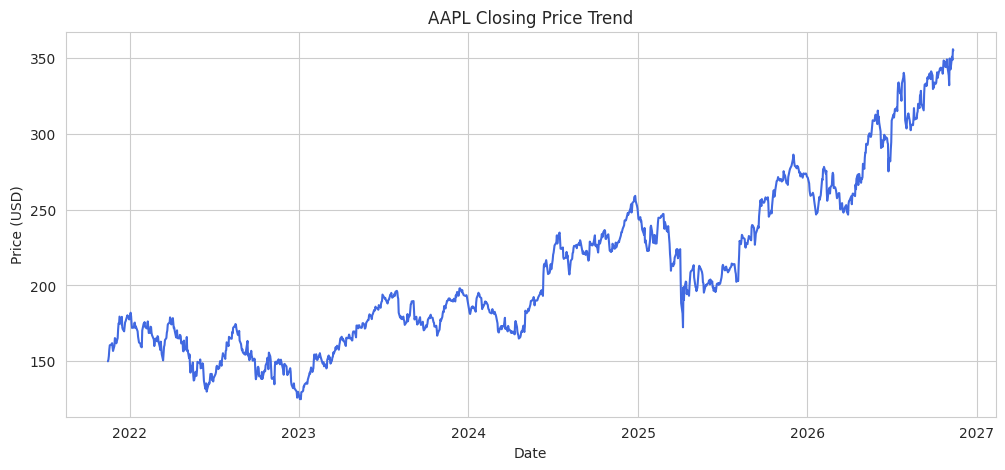

In [ ]:
df["Date"] = pd.to_datetime(df["Date"])

plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"], color="royalblue")
plt.title(f"{TICKER} Closing Price Trend")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.savefig(os.path.join(BASE_DIR, "outputs", "close_trend.png"), dpi=150, bbox_inches="tight")
plt.show()

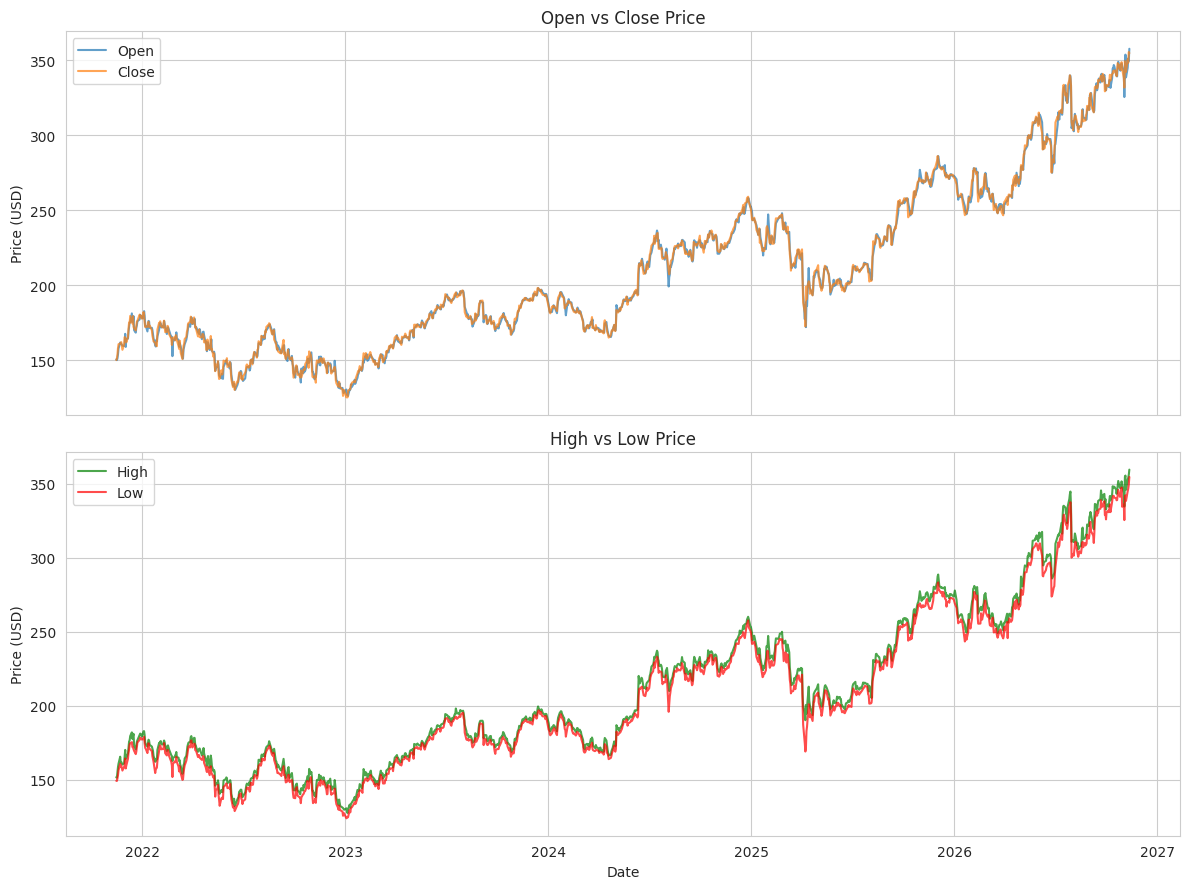

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df["Date"], df["Open"], label="Open", alpha=0.7)
axes[0].plot(df["Date"], df["Close"], label="Close", alpha=0.7)
axes[0].set_title("Open vs Close Price")
axes[0].set_ylabel("Price (USD)")
axes[0].legend()

axes[1].plot(df["Date"], df["High"], label="High", color="green", alpha=0.7)
axes[1].plot(df["Date"], df["Low"], label="Low", color="red", alpha=0.7)
axes[1].set_title("High vs Low Price")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Price (USD)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "outputs", "open_close_high_low.png"), dpi=150, bbox_inches="tight")
plt.show()

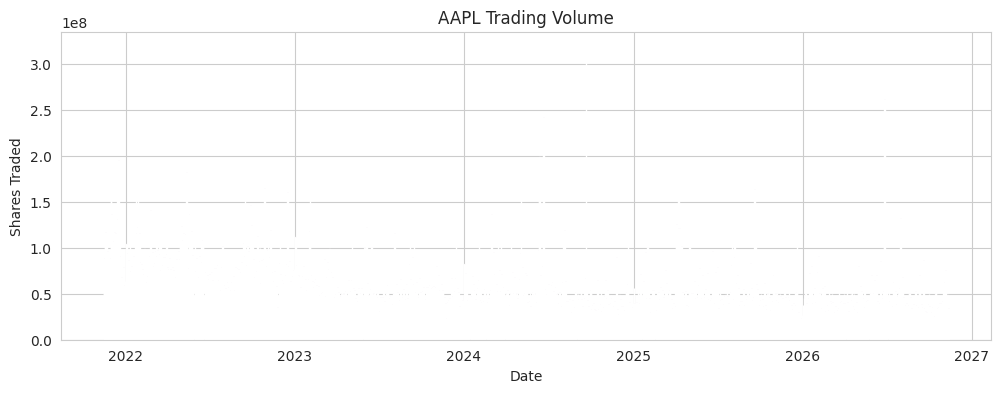

In [ ]:
plt.figure(figsize=(12, 4))
plt.bar(df["Date"], df["Volume"], color="purple", width=1.0)
plt.title(f"{TICKER} Trading Volume")
plt.xlabel("Date")
plt.ylabel("Shares Traded")
plt.savefig(os.path.join(BASE_DIR, "outputs", "volume.png"), dpi=150, bbox_inches="tight")
plt.show()

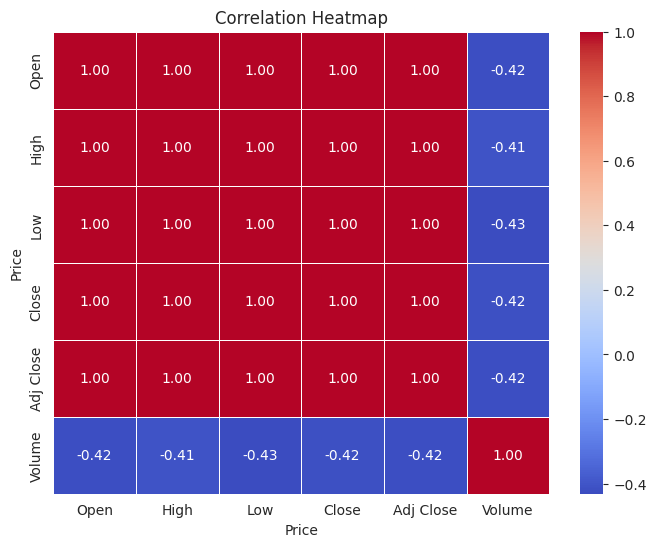

In [ ]:
corr_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.savefig(os.path.join(BASE_DIR, "outputs", "correlation_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])           # datetime format
data = data.drop_duplicates()                          # duplicates hatao
data = data.sort_values("Date").reset_index(drop=True) # chronological order
data = data.ffill().dropna()                           # missing values handle

# Sirf zaroori columns (Adj Close ko Close ke qareeb hone ki wajah se chor diya)
data = data[["Date", "Open", "High", "Low", "Close", "Volume"]]
print("Shape after cleaning:", data.shape)

Shape after cleaning: (1254, 6)


In [ ]:
# Lag feature
data["Prev_Close"] = data["Close"].shift(1)

# Moving averages (sirf aaj aur pichle dinon ka data)
for window in [5, 10, 20]:
    data[f"MA_{window}"] = data["Close"].rolling(window=window).mean()

# Daily changes
data["Daily_Change"] = data["Close"] - data["Prev_Close"]
data["Daily_Pct_Change"] = data["Close"].pct_change() * 100

# Target: agle trading din ki Close price
data["Target"] = data["Close"].shift(-1)

# Aakhri row ko future prediction ke liye alag rakh lo (iska Target NaN hai)
latest_row = data.iloc[[-1]].copy()

# NaN rows hatao (rolling/lag/shift se bani hain)
model_df = data.dropna().reset_index(drop=True)

print("Final shape:", model_df.shape)
model_df.to_csv(os.path.join(BASE_DIR, "data", f"{TICKER}_processed.csv"), index=False)
model_df.head()

Final shape: (1234, 13)


Price,Date,Open,High,Low,Close,Volume,Prev_Close,MA_5,MA_10,MA_20,Daily_Change,Daily_Pct_Change,Target
0,2021-12-13,181.119995,182.130005,175.529999,175.740005,153237000,179.449997,175.201999,169.700,163.566501,-3.709991,-2.067424,174.330002
1,2021-12-14,175.250000,177.740005,172.210007,174.330002,139380400,175.740005,175.832001,170.603,164.783001,-1.410004,-0.802324,179.300003
2,2021-12-15,175.110001,179.500000,172.309998,179.300003,131063300,174.330002,176.676001,172.056,166.198001,4.970001,2.850916,172.259995
3,2021-12-16,179.279999,181.139999,170.750000,172.259995,150185800,179.300003,176.216000,172.906,167.136501,-7.040009,-3.926385,171.139999
4,2021-12-17,169.929993,173.470001,169.690002,171.139999,195432700,172.259995,174.554001,173.836,167.800001,-1.119995,-0.650177,169.750000


In [ ]:
check = model_df[["Date", "Close", "Target"]].head(3)
display(check)

# Har row ka Target agli row ki Close ke barabar hona chahiye
print("Target == next Close:",
      np.allclose(model_df["Target"].iloc[:-1], model_df["Close"].iloc[1:]))

Price,Date,Close,Target
0,2021-12-13,175.740005,174.330002
1,2021-12-14,174.330002,179.300003
2,2021-12-15,179.300003,172.259995


Target == next Close: True


In [ ]:
FEATURES = [
    "Open", "High", "Low", "Close", "Volume",
    "Prev_Close", "MA_5", "MA_10", "MA_20",
    "Daily_Change", "Daily_Pct_Change",
]
TARGET = "Target"

X = model_df[FEATURES]
y = model_df[TARGET]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (1234, 11) | y shape: (1234,)


In [ ]:
split_idx = int(len(model_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train = model_df["Date"].iloc[:split_idx]
dates_test = model_df["Date"].iloc[split_idx:]

print(f"Train: {len(X_train)} rows ({dates_train.iloc[0].date()} to {dates_train.iloc[-1].date()})")
print(f"Test : {len(X_test)} rows ({dates_test.iloc[0].date()} to {dates_test.iloc[-1].date()})")

Train: 987 rows (2021-12-13 to 2025-11-17)
Test : 247 rows (2025-11-18 to 2026-11-11)


In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit sirf train par
X_test_scaled = scaler.transform(X_test)         # test par sirf transform

joblib.dump(scaler, os.path.join(BASE_DIR, "models", "scaler.pkl"))
print("Scaled train mean (approx 0):", X_train_scaled.mean().round(3))

Scaled train mean (approx 0): -0.0


In [ ]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)          # scaled data par train

y_pred_lr = lr_model.predict(X_test_scaled)    # test predictions
joblib.dump(lr_model, os.path.join(BASE_DIR, "models", "linear_regression.pkl"))

print("Linear Regression trained. Sample predictions:", y_pred_lr[:3].round(2))

Linear Regression trained. Sample predictions: [267.83 268.63 266.64]


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5],
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

rf_model = grid.best_estimator_
y_pred_rf = rf_model.predict(X_test)
joblib.dump(rf_model, os.path.join(BASE_DIR, "models", "random_forest.pkl"))

print("Best parameters:", grid.best_params_)
print("Sample predictions:", y_pred_rf[:3].round(2))

Best parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Sample predictions: [269.3  269.11 269.65]


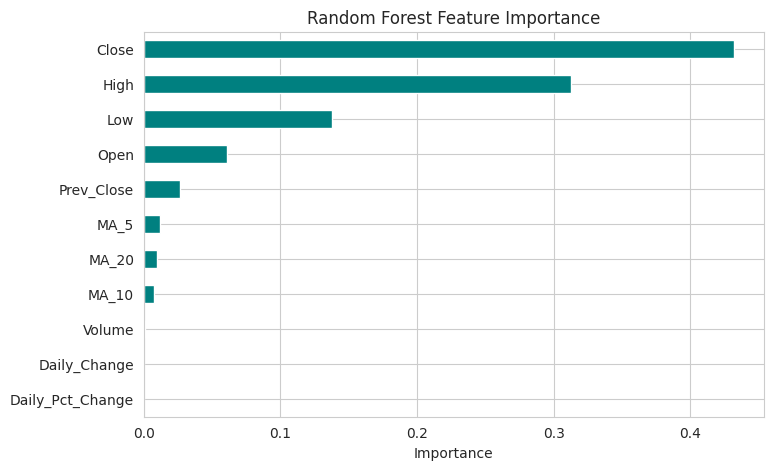

In [ ]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="teal")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.savefig(os.path.join(BASE_DIR, "outputs", "feature_importance.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, y_true, y_pred):
    """Return MAE, MSE, RMSE and R2 for one model."""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

In [ ]:
results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, y_pred_lr),
    evaluate_model("Random Forest", y_test, y_pred_rf),
]).set_index("Model")

display(results.round(4))
results.to_csv(os.path.join(BASE_DIR, "outputs", "model_comparison.csv"))

best = results["RMSE"].idxmin()
print(f"Lowest RMSE (best model on this test set): {best}")

,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,3.4987,23.9118,4.8900,0.9752
Random Forest,28.5141,1489.8537,38.5986,-0.5430


Lowest RMSE (best model on this test set): Linear Regression


In [ ]:
y_pred_naive = X_test["Close"].values      # kal ka prediction = aaj ki Close
naive = evaluate_model("Naive (today's Close)", y_test, y_pred_naive)
display(pd.concat([results, pd.DataFrame([naive]).set_index("Model")]).round(4))

,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,3.4987,23.9118,4.8900,0.9752
Random Forest,28.5141,1489.8537,38.5986,-0.5430
Naive (today's Close),3.3798,22.1680,4.7083,0.9770


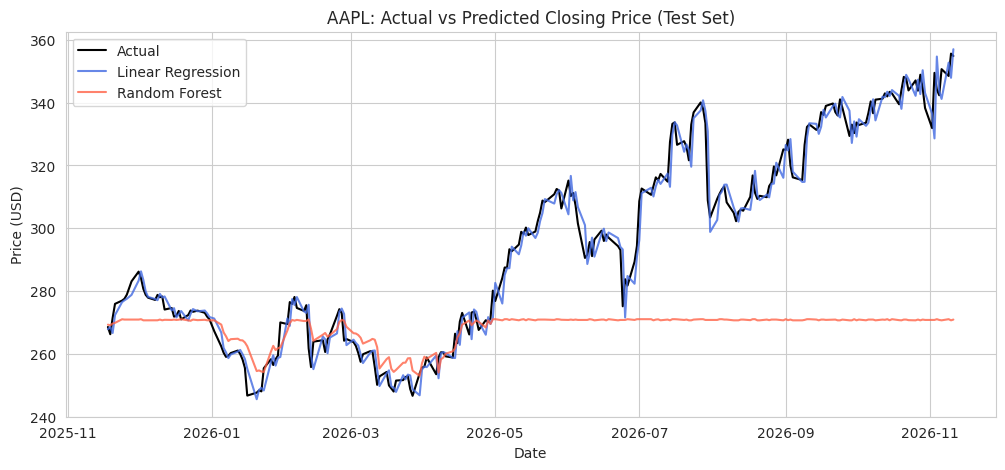

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(dates_test, y_test.values, label="Actual", color="black")
plt.plot(dates_test, y_pred_lr, label="Linear Regression", color="royalblue", alpha=0.8)
plt.plot(dates_test, y_pred_rf, label="Random Forest", color="tomato", alpha=0.8)
plt.title(f"{TICKER}: Actual vs Predicted Closing Price (Test Set)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.savefig(os.path.join(BASE_DIR, "outputs", "actual_vs_predicted.png"), dpi=150, bbox_inches="tight")
plt.show()

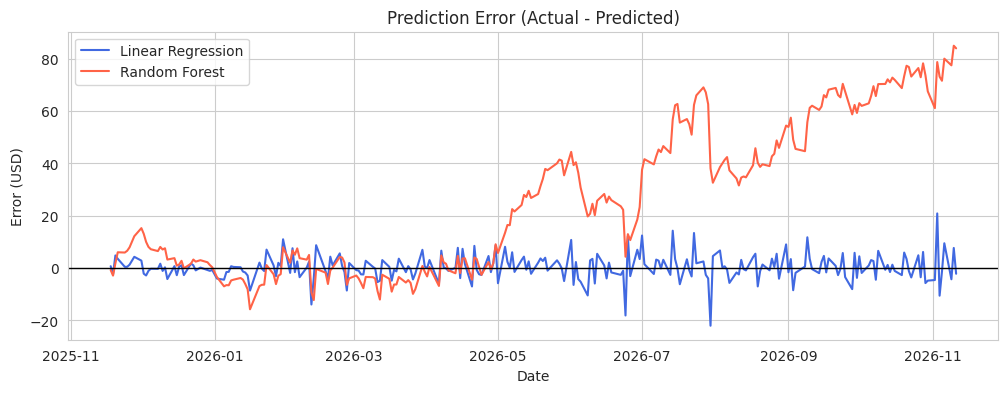

In [ ]:
err_lr = y_test.values - y_pred_lr
err_rf = y_test.values - y_pred_rf

plt.figure(figsize=(12, 4))
plt.plot(dates_test, err_lr, label="Linear Regression", color="royalblue")
plt.plot(dates_test, err_rf, label="Random Forest", color="tomato")
plt.axhline(0, color="black", linewidth=1)
plt.title("Prediction Error (Actual - Predicted)")
plt.xlabel("Date")
plt.ylabel("Error (USD)")
plt.legend()
plt.savefig(os.path.join(BASE_DIR, "outputs", "prediction_error.png"), dpi=150, bbox_inches="tight")
plt.show()

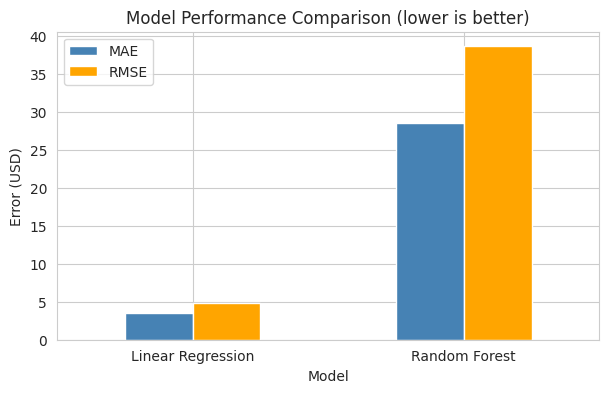

In [ ]:
results[["MAE", "RMSE"]].plot(kind="bar", figsize=(7, 4), color=["steelblue", "orange"])
plt.title("Model Performance Comparison (lower is better)")
plt.ylabel("Error (USD)")
plt.xticks(rotation=0)
plt.savefig(os.path.join(BASE_DIR, "outputs", "model_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

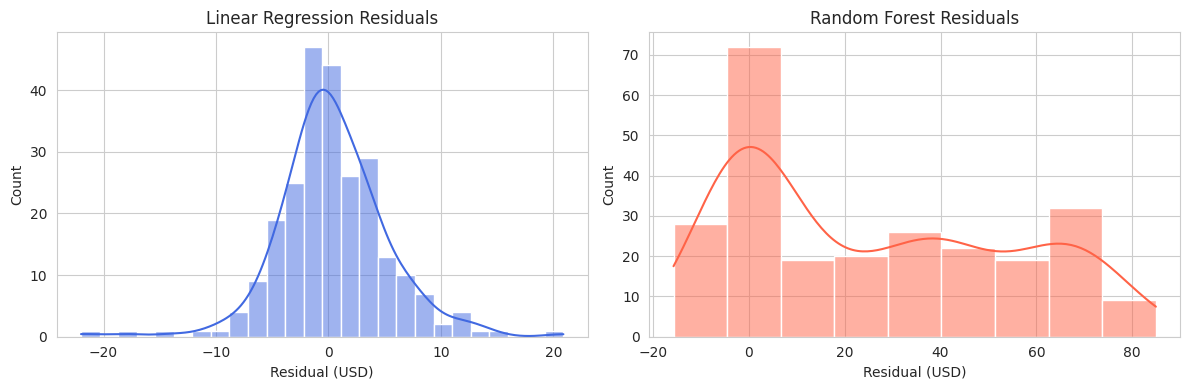

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(err_lr, kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Linear Regression Residuals")
sns.histplot(err_rf, kde=True, ax=axes[1], color="tomato")
axes[1].set_title("Random Forest Residuals")
for ax in axes:
    ax.set_xlabel("Residual (USD)")
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "outputs", "residuals.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
def predict_next_day(model, scaler, latest_row, features, use_scaling):
    """Predict the next trading day's Close from the latest available row."""
    try:
        X_new = latest_row[features]
        if use_scaling:
            X_new = scaler.transform(X_new)
        predicted = float(model.predict(X_new)[0])
        latest_close = float(latest_row["Close"].iloc[0])
        return latest_close, predicted, predicted - latest_close
    except Exception as e:
        print("Prediction error:", e)
        return None

latest_date = latest_row["Date"].iloc[0].date()
print(f"Latest data date: {latest_date}\n")

for name, model, scaled in [
    ("Linear Regression", lr_model, True),
    ("Random Forest", rf_model, False),
]:
    out = predict_next_day(model, scaler, latest_row, FEATURES, scaled)
    if out:
        last, pred, diff = out
        print(f"{name}")
        print(f"  Latest actual Close : ${last:,.2f}")
        print(f"  Predicted next Close: ${pred:,.2f}")
        print(f"  Predicted difference: ${diff:+,.2f}\n")

print("NOTE: Experimental forecast only. Not financial advice.")

Latest data date: 2026-11-12

Linear Regression
  Latest actual Close : $354.88
  Predicted next Close: $354.66
  Predicted difference: $-0.22

Random Forest
  Latest actual Close : $354.88
  Predicted next Close: $270.69
  Predicted difference: $-84.19

NOTE: Experimental forecast only. Not financial advice.


In [ ]:
!zip -r /content/project.zip /content/stock_price_prediction

  adding: content/stock_price_prediction/ (stored 0%)
  adding: content/stock_price_prediction/notebooks/ (stored 0%)
  adding: content/stock_price_prediction/requirements.txt (deflated 8%)
  adding: content/stock_price_prediction/models/ (stored 0%)
  adding: content/stock_price_prediction/models/linear_regression.pkl (deflated 14%)
  adding: content/stock_price_prediction/models/scaler.pkl (deflated 30%)
  adding: content/stock_price_prediction/models/random_forest.pkl (deflated 69%)
  adding: content/stock_price_prediction/outputs/ (stored 0%)
  adding: content/stock_price_prediction/outputs/model_comparison.png (deflated 17%)
  adding: content/stock_price_prediction/outputs/open_close_high_low.png (deflated 5%)
  adding: content/stock_price_prediction/outputs/close_trend.png (deflated 6%)
  adding: content/stock_price_prediction/outputs/model_comparison.csv (deflated 25%)
  adding: content/stock_price_prediction/outputs/prediction_error.png (deflated 5%)
  adding: content/stock_pri

In [ ]:
from google.colab import files; files.download('/content/project.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>